# TD 3: Replay of the neural activity during sleep after a task

Understanding how memories are stored and consolidated in the brain is one of the fundamental goals
of neuroscience. It is known that short term memories are stored in the brain area called the hippocampus
while long term memories are stored in the brain area called the prefrontal cortex. It is important to better
understand how memories are transmitted from the hippocampus to the cortex and what is the role of sleep
for memory consolidation and learning processes. To such aim, multi-electrode recording of a few dozens of
neurons in the prefrontal cortex of alive rats have been performed by F. Battaglia’s group [[1](https://hal.science/hal-00551868), [2](https://pmc.ncbi.nlm.nih.gov/articles/PMC2940043/)]. A single
recording session, in which the same neurons are recorded, is divided into three epochs: 
- a $task$ epoch in
which the rat has to learn, by trials and errors, what is the rewarded arm in a Y-shaped maze (there are
four possible rules which are changed by the operator as soon as the rat learns them: go to the left arm, go
to the right arm, go where a light is on, go where a light is off);
- a $pre-task$ sleep epoch;
- a $post-task$ sleep epoch.

**The goal of this tutorial is to analyze the recording data using principal component
analysis and tools from random matrix theory**, in order to detect similarities between the neuronal activity
during the $task$ and during the $post-task$ sleep epochs, which were not present in the $pre-task$ sleep epoch.
OBS: The paper uses many sessions to draw their results. We will only use the data of one session.

![PrePost.png](PrePost.png)
**Caption:** Reactivation strength (black and white traces; right axes) of the signal component during sleep pre (left) and
post (right) epochs superimposed on the spectrogram (left axes). White traces indicate slow-wave sleep (SWS) periods and black traces indicate non-SWS. The
spectrogram shows periods of elevated slow/delta and spindle oscillations
often coinciding with SWS. Reactivation strengths show high peaks during
post epoch SWS, usually concomitant with periods of strong oscillations.

# Data:
The spiking activity of a population of $L = 37$ prefrontal cortex neurons during the


- **$pre-task$ sleep (Dati_181014_sleep1.txt)**
- **$task$ (Dati_181014_maze.txt)**
- **$post-task$ sleep (Dati_181014_sleep2.txt)**

epochs can be downloaded from the course webpage, see Tutorial 3 repository. Each file contains a two-
column array $\lbrace t_i , i \rbrace$, where $t_i$ is a spiking time of neuron $i$ (**times are in units of 0.1 ms**), ranging between
$T_{min}$ and $T_{max}$ , and $i$ is the neuron index. Data are taken from Ref. [[1](https://hal.science/hal-00551868)].

# Problem
During a recording session, $L$ neurons, labeled by $i = 1, \ldots , L$, are recorded for a total time $T$ . Following
Refs. [1, 2], we will discretize the spike trains in $\Delta t = 100 ms$ time bin. We call $M = T /\Delta t$ the total
number of bins, and $t_b$ the time corresponding to the center of the $b^{th}$ bin, $b = 1, \ldots , M$ . The activity of
a neuron $i$ in a time bin $[t_b − \Delta t/2, t_b +  \Delta t/2]$ is represented by a spike count variable $s_i (t_b ) = 0, 1, 2, . . .$.

**Pearson correlation matrix:** We define the mean and variance of $s_i$ over time as:

$$ p_i=\left\langle s_i\right\rangle =\frac{1}{M}\sum_{b=1}^M s_i(t_b)$$

$$ \sigma_i^2=\frac{1}{M-1}\sum_{b=1}^M (s_i(t_b)-p_i)^2$$

The $z-score$ variables, which will be our data, are defined as

$$y_{b,i}=\frac{s_i(t_b)-p_i}{\sigma_i}$$

which defines a $M \times L$ matrix $Y=(y_{b,i})$. Each column $\boldsymbol{y}_i=(y_{b,i})_{1\leq b\leq M}$ of the matrix defines a realization of the spiking process of
the $L$ neurons, and we have $M$ such realizations available, each corresponding to a different time. We define
the $L \times L$ Pearson correlation matrix as:

$$ C=\frac{1}{M}Y^T Y$$
or equivalently,
$$ C_{i,j}=\frac{1}{M}\sum_{b=1}^M y_{b,i}y_{b,j}.$$

The matrix element $C_{i,j}$ encodes the correlation, averaged over time, of a pair of neurons $i$, $j$. Such matrix can
be diagonalized to find its eigenvectors and eigenvalues. The central part of the spectrum of the eigenvalues
is due to sampling noise, and therefore it follows a Marchenko-Pastur law of parameter $r = L/M < 1$:

$$ \rho(\lambda)=\frac{1}{2\pi} \frac{\sqrt{(\lambda_+-\lambda)(\lambda-\lambda_-)}}{r\lambda}, ~ \lambda_{\pm}=(1\pm \sqrt{r})^2.$$

In order to extract the signal components, we must select the eigenvalues that fall outside the interval
$[\lambda_- , \lambda_+ ]$.

In [1]:
import numpy as np
import math
import matplotlib.pyplot as plt
from scipy.sparse import coo_matrix
import numpy.matlib
import pandas as pd
from IPython.display import display, Math

# Set global font sizes for labels and ticks
plt.rcParams['axes.labelsize'] = 20    # axis labels (xlabel, ylabel)
plt.rcParams['xtick.labelsize'] = 16   # x-axis tick labels
plt.rcParams['ytick.labelsize'] = 16   # y-axis tick labels

L = 37
DT_TICKS = 1000            # 100 ms / (0.1 ms per timestamp unit)
DT_SECONDS = 0.1

### Question 1 - Read and visualize the recordings
Read the data and produce the raster plot for the $L$ neurons and the first $10$ seconds of the activity. Note
that in reading the data, you should find $T_{min}$ and $T_{max}$ for each epoch.

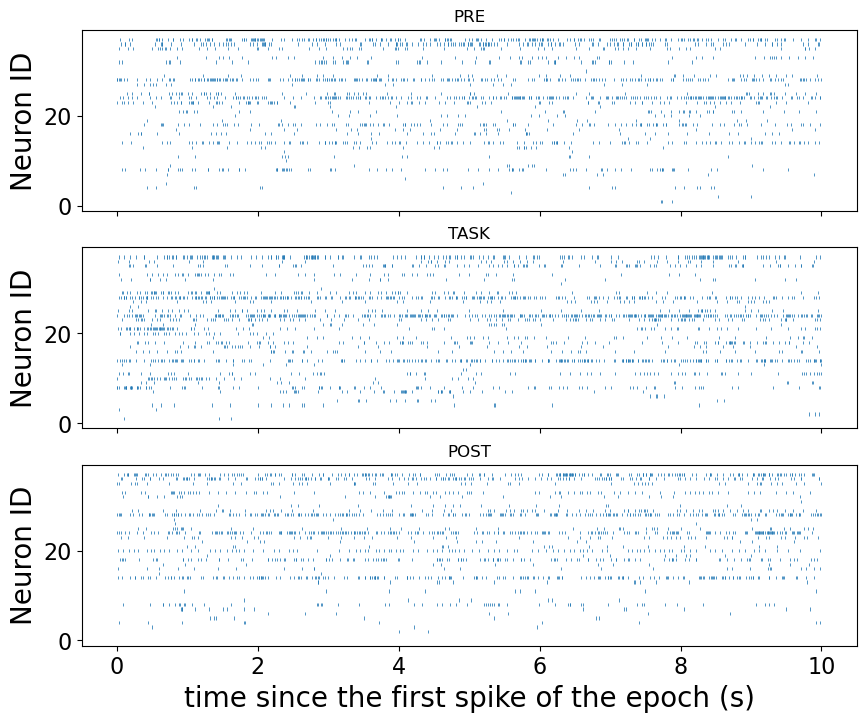

In [2]:
#take the data in the task epoch
datapaths = ('Data/Dati_181014_sleep1.txt','Data/Dati_181014_maze.txt','Data/Dati_181014_sleep2.txt')
labels = ('PRE', 'TASK', 'POST')

fix, axes = plt.subplots(3,1,figsize=(10,8), sharex=True,sharey=True)


for ax,path, label in zip(axes,datapaths,labels):
    data = np.loadtxt(path)
    Ndata = np.size(data,0)
    t_min = np.min(data[:,0])
    t_max = np.max(data[:,0])
    
    t_seconds = (data[:,0]-t_min)/(10_000)
    first_10_s = t_seconds < 10
    ax.vlines(t_seconds[first_10_s],data[first_10_s,1]-0.35, data[first_10_s,1]+0.35,lw=0.55)
    ax.set_title(label)
    ax.set_ylabel("Neuron ID")

axes[-1].set_xlabel("time since the first spike of the epoch (s)")
plt.show()

### Question 2 - bin spikes and count distributions
In this question, we consider only the $task$ data.

##### Question 2 (i): 
Write a function that takes the data (which are binary) and compute the $M\times L$ matrix $(s_i(t_b))_{b,i}$ with the discretization time bin $\Delta t=100 ms$ (we recall that data are obtained every $0.1ms$). 
Compare the observed ocunt distribution with Poisson distribution (available in `scipy.stats.poisson`, submodule `pmf`) of the same mean, both after pooling all neurons and for one individual neuron. Use a logarithmic vertical axis so that the tails are visible.

In [3]:
task_data = np.loadtxt('Data/Dati_181014_maze.txt')
task_data.shape # two columns: time, neuron id
tmin_task = min(task_data[:,0])
tmax_task = max(task_data[:,0])
M = int((tmax_task - tmin_task) / DT_TICKS) + 1

def spike_counts(data):
    tmin = min(data[:,0])
    tmax = max(data[:,0])

    M = int((tmax - tmin) / DT_TICKS) + 1
    matrix = np.zeros((M, L))

    for i in range(1, L+1):
        ind = (data[:,1]==i) # neuron indices
        times = data[ind,0] - tmin # neuron times (start at time 0)
        for b in range(M):
            time_window = np.logical_and(times>=b*DT_TICKS, times<(b+1)*DT_TICKS)
            matrix[b, i-1] = np.sum(time_window)
            
    return matrix

sis = spike_counts(task_data)

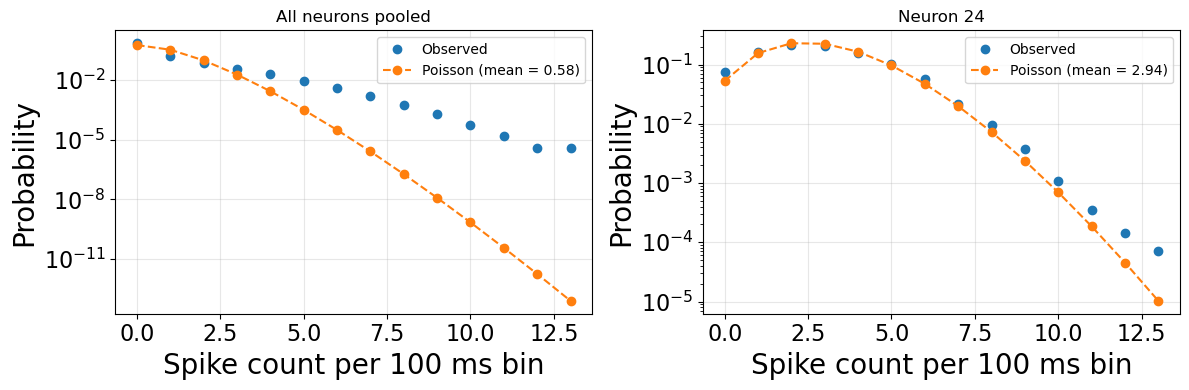

In [4]:
from scipy.stats import poisson

neuron_id = 24  # choose any neuron from 1 to L

datasets = [
    (sis.ravel(), "All neurons pooled"),
    (sis[:, neuron_id - 1], f"Neuron {neuron_id}")
]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, (counts, title) in zip(axes, datasets):
    counts = counts.astype(int)
    mean_count = counts.mean()

    # Observed probability for each possible spike count
    k = np.arange(counts.max() + 1)
    observed = np.bincount(counts, minlength=len(k)) / counts.size

    # Zero probabilities cannot be displayed on a logarithmic axis
    nonzero = observed > 0
    ax.plot(k[nonzero], observed[nonzero], "o",
            label="Observed")
    ax.plot(k, poisson.pmf(k, mu=mean_count), "o--",
            label=f"Poisson (mean = {mean_count:.2f})")

    ax.set_yscale("log")
    ax.set_xlabel("Spike count per 100 ms bin")
    ax.set_ylabel("Probability")
    ax.set_title(title)
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

##### Question 2 (ii):
Compute the Pearson correlation matrix of the $task$ activity and diagonalize it. Compare the spectrum
of eigenvalues of $C$ task to the Marchenko-Pastur distribution to extract the signal components associated to
large eigenvalues. How many signal components with $\lambda > \lambda_+$ are present? Use `np.linalg.eigh`.

In [5]:
Y = (sis - np.mean(sis, axis=0)[None,:]) / np.std(sis, axis=0, ddof=1)[None, :]
M = sis.shape[0]

C_task = Y.T @ Y / M

eigvals_task, eigvecs_task = np.linalg.eigh(C_task)
eigenvalues = eigvals_task  # keeping this name for the plot just below

r = L / M
lambda_p = (1 + np.sqrt(r))**2
lambda_m = (1 - np.sqrt(r))**2
n_signal = np.sum(eigvals_task > lambda_p)

print("lambda+ =", lambda_p)
print("number of components above lambda+:", n_signal)
print("largest eigenvalues:", eigvals_task[-8:][::-1])


lambda+ = 1.1051298252768913
number of components above lambda+: 6
largest eigenvalues: [2.15053293 1.46432679 1.33707928 1.30636579 1.16323993 1.12384063
 1.10377538 1.07548894]


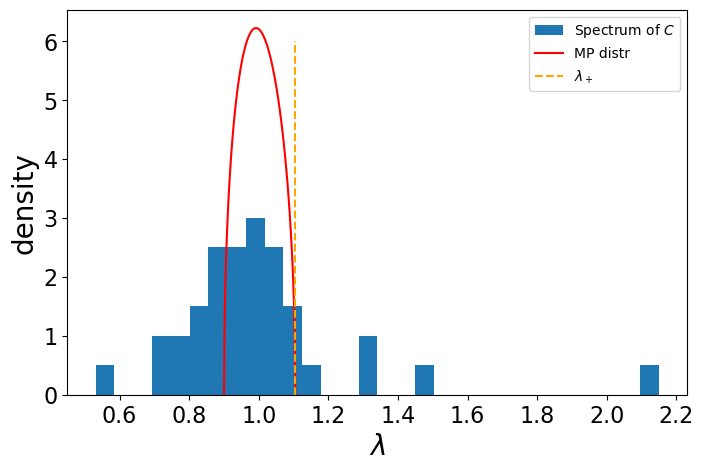

In [6]:
plt.figure(figsize=(8, 5))

xs = np.linspace(lambda_m, lambda_p, 100)
mp_distr = np.sqrt((lambda_p - xs) * (xs - lambda_m)) / (2*np.pi*r*xs)

plt.hist(eigenvalues, bins=30, density=True, label=r"Spectrum of $C$")
plt.plot(xs, mp_distr, color="red", label="MP distr")
plt.vlines(lambda_p, 0, 6, color="orange", linestyles="--", label=r"$\lambda_+$")
plt.xlabel(r"$\lambda$")
plt.ylabel("density")
plt.legend()
plt.show()


### Question 3 - Shuffling the data

Reshuffle the data, by randomly permuting the activity of the single neurons over the $M$ possible time
bins, in such a way that the correlations between neurons spiking together are lost, but the frequencies of
individual neurons are kept constant. Verify that the spectrum of the eigenvalues of the Pearson correlation
matrix of the shuffled data is well described by the Marchenko-Pastur distribution.

### Question 4 - Which neurons contribute to the top component?

Identify the neurons that contribute the most to the largest component of the task activity (largest entries in the eigenvector associated to the top eigenvalue). These neurons
identify a cell assembly of neurons coactivating during the task. **In `np.linalg.eigh`, the $i^{th}$ eigenvector corresponds to `eigvecs[:, -i]`**. 

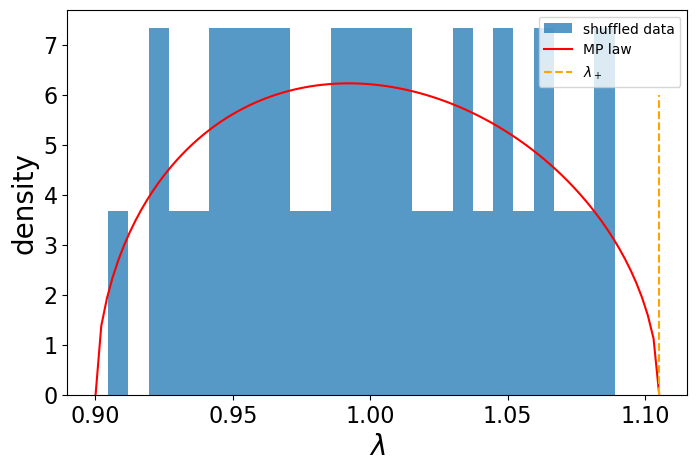

components above lambda+ after shuffling: 0


In [7]:
rng = np.random.default_rng(3)

sis_shuffled = sis.copy()
for i in range(L):
    rng.shuffle(sis_shuffled[:, i])

Y_shuffled = (sis_shuffled - np.mean(sis_shuffled, axis=0)[None, :]) / np.std(sis_shuffled, axis=0, ddof=1)[None, :]
C_shuffled = Y_shuffled.T @ Y_shuffled / M
shuffled_eigvals = np.linalg.eigh(C_shuffled)[0]

plt.figure(figsize=(8, 5))
plt.hist(shuffled_eigvals, bins=25, density=True, alpha=0.75, label="shuffled data")
plt.plot(xs, mp_distr, color="red", label="MP law")
plt.vlines(lambda_p, 0, 6, color="orange", linestyles="--", label=r"$\lambda_+$")
plt.xlabel(r"$\lambda$")
plt.ylabel("density")
plt.legend()
plt.show()

print("components above lambda+ after shuffling:", np.sum(shuffled_eigvals > lambda_p))


After shuffling, the spectrum is much closer to the MP bulk. This is what I expected: each neuron keeps its firing count distribution, but the common timing between neurons has mostly disappeared.


# Replay: 
We want to identify the similarity in the correlation structure between the sleep neuronal activity
(in the pre-task or post-task epochs) and the task activity. Following Peyrache et al. [[2](https://pmc.ncbi.nlm.nih.gov/articles/PMC2940043/)], the task epoch is called
the template epoch, while the pre-task or post-task sleep epochs are called match epochs.
Each epoch's neurons are standardized within that epoch.
 An instantaneous
measure of similarity in the correlated activity is obtained by computing the scalar product, over all the
pairs of neurons, of the simultaneous co-activation of the pair during the match and the corresponding pair
correlation during the template,

$$  R^{match}(t_b)=\frac{1}{2} \sum_{i \neq j} y_{b,i}^{match} C_{i,j}^{template} y_{b,j}^{match}.  $$

Keeping only distinct neuron paris avoids letting one unusually active neuron dominate the match score (or replay).
Time averaging gives an equivalent correlation-matrix comparison

$$ \bar{R}^{match}= \frac{1}{M_{match}}\sum_b R^{match}(t_b)=\frac{1}{2} \sum_{i \neq j}  C_{i,j}^{template} C_{i,j}^{match} \approx \frac{1}{2}\text{Tr}\left[ (C^{match}-I)(C^{template}-I) \right],$$

where $\text{Tr}$ is the trace operation, $I$ is the identity matrix, and we used that, by definition, $C_{i,i} = (M −1)/M \approx 1$.

 Using the eigenvalue decomposition $C_{i,j}
= \sum_{k=1}^{L} \lambda_k v_i^{(k)} v_j^{(k)}$ in Eq. (5), one obtains the time-dependent
replay as a sum of replays associated to each principal component:

$$ R^{match}(t_b)= \sum_{k=1}^{L} \lambda_k R_k^{match}(t_b),$$

where 

$$ R_k^{match}(t_b)=\frac{1}{2}\left[ \left( \sum_{i=1}^L y_{b,i}^{match}v_i^{(k)} \right)^2 - \sum_{i=1}^L \left(y_{b,i}^{match}v_i^{(k)}\right)^2 \right] $$
 keeping in mind that $\boldsymbol{v}^{(k)}$ are the eigenvectors associated to the template epoch.

Top eigenvalue: 2.1505329296818227
Most contributing neurons:
1 neuron 20 loading = 0.48857060603609753 abs = 0.48857060603609753
2 neuron 21 loading = 0.42966551891876675 abs = 0.42966551891876675
3 neuron 1 loading = 0.305755635889342 abs = 0.305755635889342
4 neuron 26 loading = 0.29401517835639757 abs = 0.29401517835639757
5 neuron 9 loading = 0.27394546277352244 abs = 0.27394546277352244
6 neuron 27 loading = -0.22419095670119946 abs = 0.22419095670119946
7 neuron 18 loading = 0.1906927560209751 abs = 0.1906927560209751
8 neuron 14 loading = -0.18770263628683792 abs = 0.18770263628683792
9 neuron 8 loading = 0.16575108879808792 abs = 0.16575108879808792
10 neuron 11 loading = 0.16557683210486945 abs = 0.16557683210486945


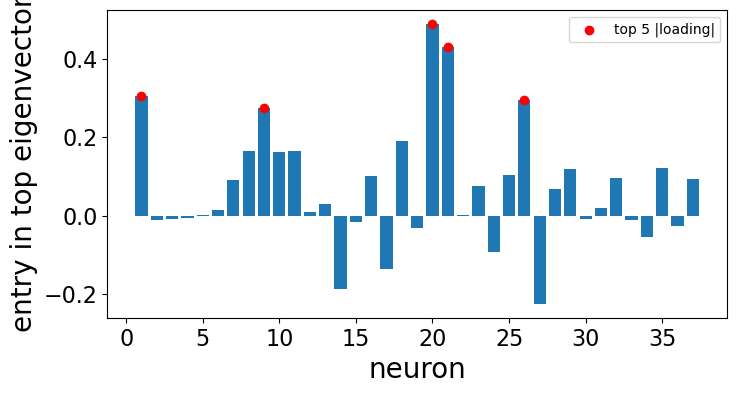

In [8]:
top_vec = eigvecs_task[:, -1]
contrib = np.abs(top_vec)
order = np.argsort(contrib)[::-1]

print("Top eigenvalue:", eigvals_task[-1])
print("Most contributing neurons:")
for rank, i in enumerate(order[:10], start=1):
    print(rank, "neuron", i + 1, "loading =", top_vec[i], "abs =", contrib[i])

plt.figure(figsize=(8, 4))
plt.bar(np.arange(1, L+1), top_vec)
plt.scatter(order[:5] + 1, top_vec[order[:5]], color="red", zorder=3, label="top 5 |loading|")
plt.xlabel("neuron")
plt.ylabel("entry in top eigenvector")
plt.legend()
plt.show()


The sign of an eigenvector is arbitrary, so I used the absolute value of the loading to rank the neurons. The largest entries are the neurons that contribute most to this task-related assembly.


### Question 5 - Average TASK-pattern similarity in PRE and POST
Calculate the total replay of the pre-task sleep and post-task sleep epochs, with respect to the task epoch.

### Question 6 — When does matching activity occur?

Plot the replay as a function of time in the pre-task and post-task sleep epochs. Is
it constant in time? Compare with the results in Fig. 2 of Ref. [2].

In [9]:
pre_data = np.loadtxt('Data/Dati_181014_sleep1.txt')
post_data = np.loadtxt('Data/Dati_181014_sleep2.txt')

pre_sis = spike_counts(pre_data)
post_sis = spike_counts(post_data)

def zscore_matrix(counts):
    return (counts - np.mean(counts, axis=0)[None, :]) / np.std(counts, axis=0, ddof=1)[None, :]

def corr_matrix(counts):
    Y_epoch = zscore_matrix(counts)
    return Y_epoch.T @ Y_epoch / Y_epoch.shape[0], Y_epoch

C_pre, Y_pre = corr_matrix(pre_sis)
C_post, Y_post = corr_matrix(post_sis)

def replay_trace(Y_match, C_template):
    # remove the diagonal, since the formula only uses distinct neuron pairs
    C0 = C_template.copy()
    np.fill_diagonal(C0, 0)
    return 0.5 * np.einsum('bi,ij,bj->b', Y_match, C0, Y_match)

R_pre = replay_trace(Y_pre, C_task)
R_post = replay_trace(Y_post, C_task)

print("average replay PRE :", np.mean(R_pre))
print("average replay POST:", np.mean(R_post))
print("POST - PRE:", np.mean(R_post) - np.mean(R_pre))


average replay PRE : 0.29070797006988924
average replay POST: 0.5480940812640069
POST - PRE: 0.2573861111941177


Here the POST average should be interpreted relative to the PRE baseline. A higher POST value means that the correlation pattern seen during the task reappears more strongly after the task than before it.


![Fig2_2](Fig2_2.png)

### Question 7 - The top TASK component

Plot the first principal component of the replay $R^{match}_1(t_b)$ as a function of time in the pre-task and post-task sleep epochs. Is
it constant in time? Compare with the results of Question 6.

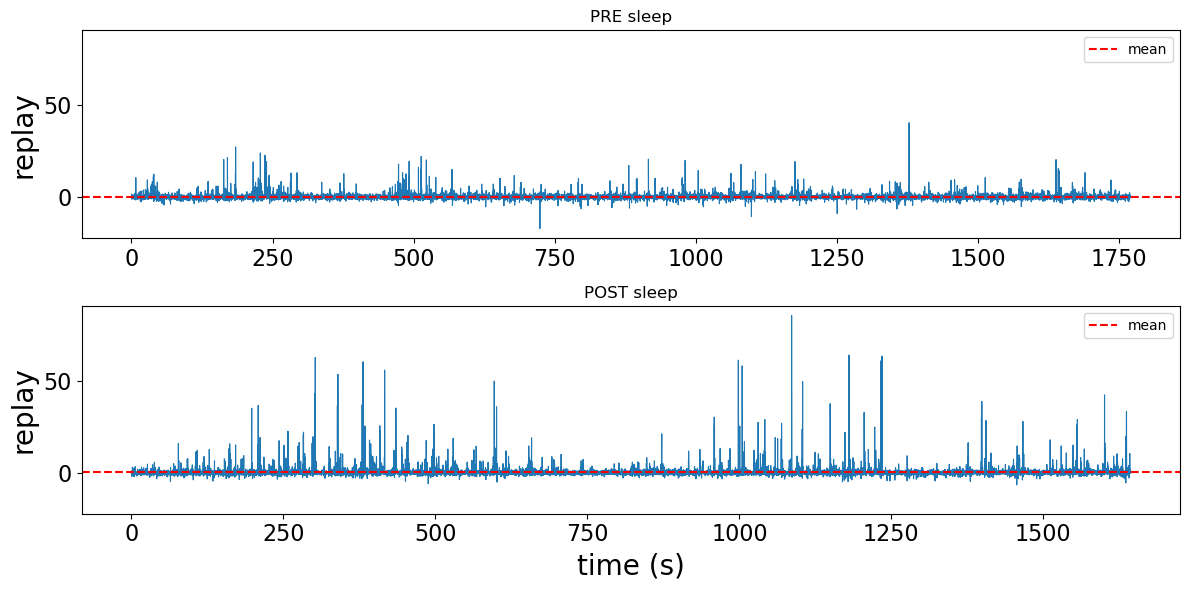

In [10]:
time_pre = np.arange(len(R_pre)) * DT_SECONDS
time_post = np.arange(len(R_post)) * DT_SECONDS

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharey=True)
for ax, t, R, title in zip(axes, [time_pre, time_post], [R_pre, R_post], ["PRE sleep", "POST sleep"]):
    ax.plot(t, R, lw=0.8)
    ax.axhline(np.mean(R), color="red", ls="--", lw=1.5, label="mean")
    ax.set_title(title)
    ax.set_ylabel("replay")
    ax.legend()

axes[-1].set_xlabel("time (s)")
plt.tight_layout()
plt.show()


The replay is not constant in time. It has short peaks, which is qualitatively close to the idea in Fig. 2: the task pattern comes back in brief events rather than as a flat increase during the whole sleep epoch.


### Question 8 - Are strongly encoded TASK patterns stronger during POST?

For each TASK eigenvector, comput its variance during PRE and POST:
$$ \gamma_k^{match}= \boldsymbol{v}^{(k)T } C^{match} \boldsymbol{v}^{(k)} $$

Make a scatter plot of $\gamma_k$ versus $\lambda_k$ for the PRE and POST task epochs, for the components above the Question 2 MP edge.
Compare the average reactivation strength pre and post task as well, as shown Fig. 3 [2] (do a linear regression and plot the $y=x$ line). Conclude.

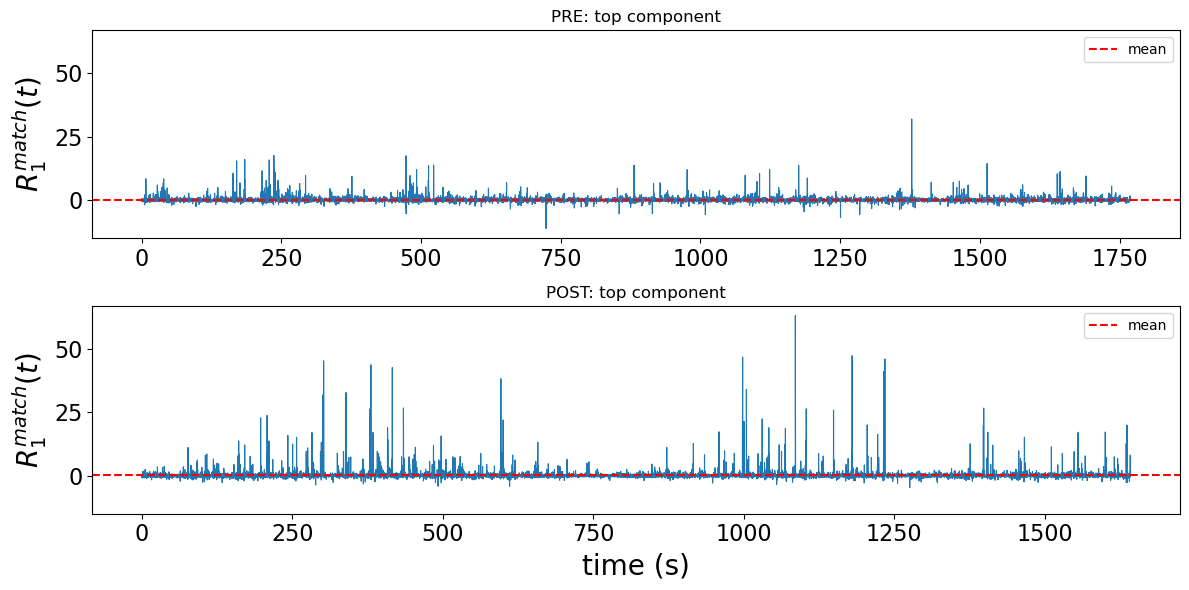

mean top-component replay PRE : 0.12020905160976685
mean top-component replay POST: 0.26578040825999466


In [11]:
v1 = eigvecs_task[:, -1]

def component_replay(Y_match, v):
    projected = Y_match @ v
    diagonal_part = (Y_match * v)**2
    return 0.5 * (projected**2 - np.sum(diagonal_part, axis=1))

R1_pre = component_replay(Y_pre, v1)
R1_post = component_replay(Y_post, v1)

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharey=True)
for ax, t, R, title in zip(axes, [time_pre, time_post], [R1_pre, R1_post], ["PRE: top component", "POST: top component"]):
    ax.plot(t, R, lw=0.8)
    ax.axhline(np.mean(R), color="red", ls="--", lw=1.5, label="mean")
    ax.set_title(title)
    ax.set_ylabel(r"$R_1^{match}(t)$")
    ax.legend()

axes[-1].set_xlabel("time (s)")
plt.tight_layout()
plt.show()

print("mean top-component replay PRE :", np.mean(R1_pre))
print("mean top-component replay POST:", np.mean(R1_post))


The top component also appears in bursts. Compared with the total replay, this plot is a bit cleaner because it isolates only the strongest task assembly instead of mixing all components together.


![Fig3_2](Fig3_2.png)

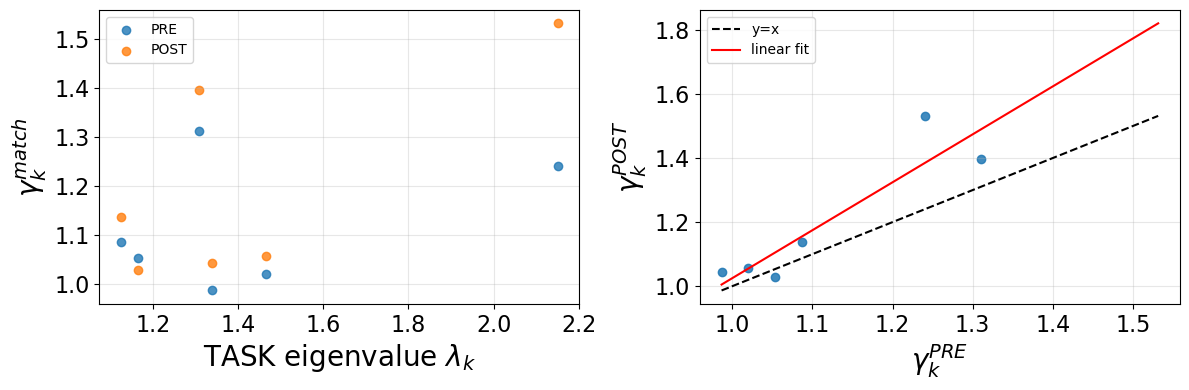

mean gamma PRE  (signal components): 1.1162074495733536
mean gamma POST (signal components): 1.198922257710156
linear fit POST = a PRE + b, a = 1.4962829651116747 b = -0.47123993461720076


In [12]:
gamma_pre = np.array([eigvecs_task[:, k].T @ C_pre @ eigvecs_task[:, k] for k in range(L)])
gamma_post = np.array([eigvecs_task[:, k].T @ C_post @ eigvecs_task[:, k] for k in range(L)])

signal = eigvals_task > lambda_p

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(eigvals_task[signal], gamma_pre[signal], label="PRE", alpha=0.8)
axes[0].scatter(eigvals_task[signal], gamma_post[signal], label="POST", alpha=0.8)
axes[0].set_xlabel(r"TASK eigenvalue $\lambda_k$")
axes[0].set_ylabel(r"$\gamma_k^{match}$")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].scatter(gamma_pre[signal], gamma_post[signal], alpha=0.85)
lo = min(gamma_pre[signal].min(), gamma_post[signal].min())
hi = max(gamma_pre[signal].max(), gamma_post[signal].max())
axes[1].plot([lo, hi], [lo, hi], "k--", label="y=x")

fit = np.polyfit(gamma_pre[signal], gamma_post[signal], 1)
xfit = np.linspace(lo, hi, 100)
axes[1].plot(xfit, fit[0]*xfit + fit[1], color="red", label="linear fit")
axes[1].set_xlabel(r"$\gamma_k^{PRE}$")
axes[1].set_ylabel(r"$\gamma_k^{POST}$")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("mean gamma PRE  (signal components):", np.mean(gamma_pre[signal]))
print("mean gamma POST (signal components):", np.mean(gamma_post[signal]))
print("linear fit POST = a PRE + b, a =", fit[0], "b =", fit[1])


The comparison is the main check here: if most signal components are above the $y=x$ line, their task-defined variance is stronger during POST than PRE. That would support the replay interpretation, while components close to the line would mean little change.


# References:

[[1](https://hal.science/hal-00551868)] Replay of rule-learning related neural patterns in the prefrontal cortex during sleep, A. Peyrache,
K. Benchenane, M. Khamassi, S. I. Wiener, F. P. Battaglia, Nature Neuroscience, DOI:10.1038/nn.2337
(2009).

[[2](https://pmc.ncbi.nlm.nih.gov/articles/PMC2940043/)] Principal component analysis of ensemble recordings reveals cell assemblies at high temporal resolution,
A. Peyrache , K. Benchenane, M. Khamassi, S. I. Wiener, F. P. Battaglia, Journal of Computational
Neuroscience, DOI:10.1007/s10827-009-0154-6 (2009).